# EXPLORATORY ANALYSIS & DESCRIPTIVE STATISTICS

Now I can start to use the analysisData table to get an idea of what the data actually says, before moving on to the statistical modelling.

Once again I import the libraries and the analysisData CSV I created at the end of the last notebook.

In [42]:
# Import libraries and analysisData csv file 
import pandas as pd 
import matplotlib.pyplot as plt

analysisData = pd.read_csv("../data/analysisData.csv")
analysisData.shape

(3895, 25)

I start by using .describe() to inspect qualiPosition, position and positionDiff. The average qaulifying and finishing positions (10 and 9) make sense, as there are almost always 20 positions available, and it is a ranking (not arbitrary). The range of position diff goes from -18 to 18, indicating that the drivers have done both 18 positions worse and better than their qualifying positions. These statistics are for the entire analysisData dataset and are not per driver or per race.

In [ ]:
# Get mean, std and percentiles for qualiPosition, position and positionDiff values
analysisData[["qualiPosition", "position", "positionDiff"]].describe()

,qualiPosition,position,positionDiff
count,3895.000000,3895.000000,3895.000000
mean,10.356098,9.168935,1.187163
std,5.900021,5.121604,3.856656
min,1.000000,1.000000,-18.000000
25%,5.000000,5.000000,-1.000000
50%,10.000000,9.000000,1.000000
75%,15.000000,13.000000,3.000000
max,22.000000,22.000000,18.000000


I chose to use Spearman correlation instead of the default Pearson correlation, as qualifying and finishing positions are rankings, and therefore the relationship is monotonic. A positive correlation in this context indicates that a driver with higher qualifying positions tends to have higher finishing positions. The overall Spearman correlation is 0.77, which is a strong positive relationship, but not perfect (qualifying and finishing position do not match consistently). 

In [ ]:
# Calculate spearman correlation for qualiPosition and position 
spearmanCorr = analysisData[["qualiPosition", "position"]].corr(method="spearman")
spearmanCorr

,qualiPosition,position
qualiPosition,1.000000,0.771365
position,0.771365,1.000000


The following is a scatter plot of qualifying position against finishing position. The reference line indicates where qualifying and finishing positions match. Any other points on the graph are where there was a difference in the two positions. The opacity of each dot assists where data points overlap, the darker a dot the more frequently this occured.

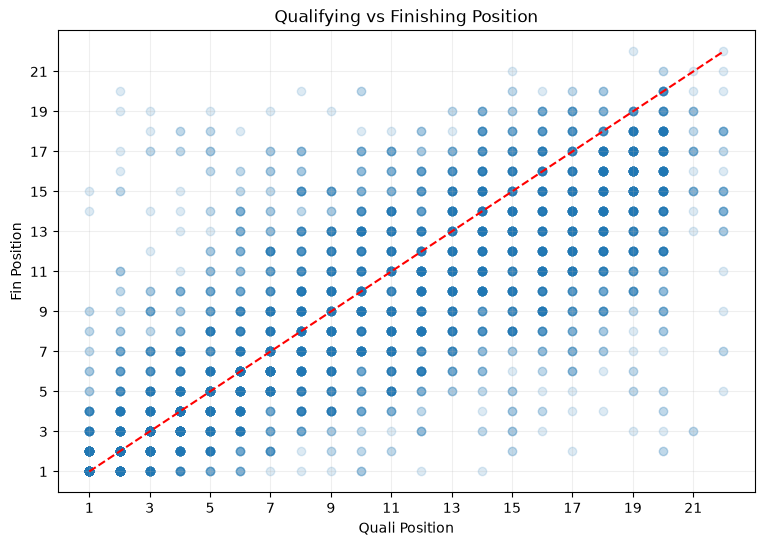

In [44]:
# Create a scatter graph of qualiPosition against position, draw a line wehre they match
plt.figure(figsize=(9,6))
plt.scatter(analysisData["qualiPosition"], analysisData["position"], alpha=0.15)
plt.plot([1,22], [1,22], linestyle="--", color="red")
plt.xlabel("Quali Position")
plt.ylabel("Fin Position")
plt.title("Qualifying vs Finishing Position")
plt.xticks(range(1,23,2))
plt.yticks(range(1,23,2))
plt.grid(alpha=0.2)
plt.show()

In [45]:
# Count number of times each circuit appears in the table and list
circuitCounts = (analysisData.groupby("circuitName").size().sort_values(ascending=False))
circuitCounts

circuitName
Red Bull Ring                           227
Bahrain International Circuit           207
Silverstone Circuit                     199
Circuit de Barcelona-Catalunya          199
Hungaroring                             194
Yas Marina Circuit                      193
Circuit de Spa-Francorchamps            191
Autodromo Nazionale di Monza            190
Autódromo José Carlos Pace              168
Circuit de Monaco                       165
Suzuka Circuit                          161
Circuit of the Americas                 161
Autódromo Hermanos Rodríguez            155
Circuit Gilles Villeneuve               150
Marina Bay Street Circuit               147
Sochi Autodrom                          138
Albert Park Grand Prix Circuit          136
Baku City Circuit                       130
Shanghai International Circuit          127
Circuit Paul Ricard                      73
Circuit Park Zandvoort                   73
Autodromo Enzo e Dino Ferrari            69
Hockenheimring      

Here I use a function to calculate the Spearman correlation between qualifying and finishing position for each circuit. Rather than calculating individual correlations for every race, I group by circuit name to get an overall result for each circuit, based on all the results achieved there.

In [ ]:
# Spearman correlation calculation function
def calculateSpearman(group):
    spearmanCorr = group["qualiPosition"].corr(group["position"],method="spearman")
    return spearmanCorr

# List the correlation for each circuit in descending order
circuitCorr = (analysisData.groupby("circuitName").apply(calculateSpearman, include_groups=False).sort_values(ascending=False))
circuitCorr

circuitName
Autodromo Internazionale del Mugello    0.916084
Autódromo Internacional do Algarve      0.857409
Circuit de Monaco                       0.856446
Circuit de Barcelona-Catalunya          0.841237
Suzuka Circuit                          0.840328
Circuit Paul Ricard                     0.838397
Autodromo Nazionale di Monza            0.821597
Autódromo Hermanos Rodríguez            0.820693
Yas Marina Circuit                      0.811564
Shanghai International Circuit          0.811282
Jeddah Corniche Circuit                 0.797471
Circuit de Spa-Francorchamps            0.794530
Circuit of the Americas                 0.790599
Albert Park Grand Prix Circuit          0.789489
Circuit Park Zandvoort                  0.770165
Circuit Gilles Villeneuve               0.769961
Miami International Autodrome           0.769887
Losail International Circuit            0.761990
Silverstone Circuit                     0.760569
Red Bull Ring                           0.755277
Marina B

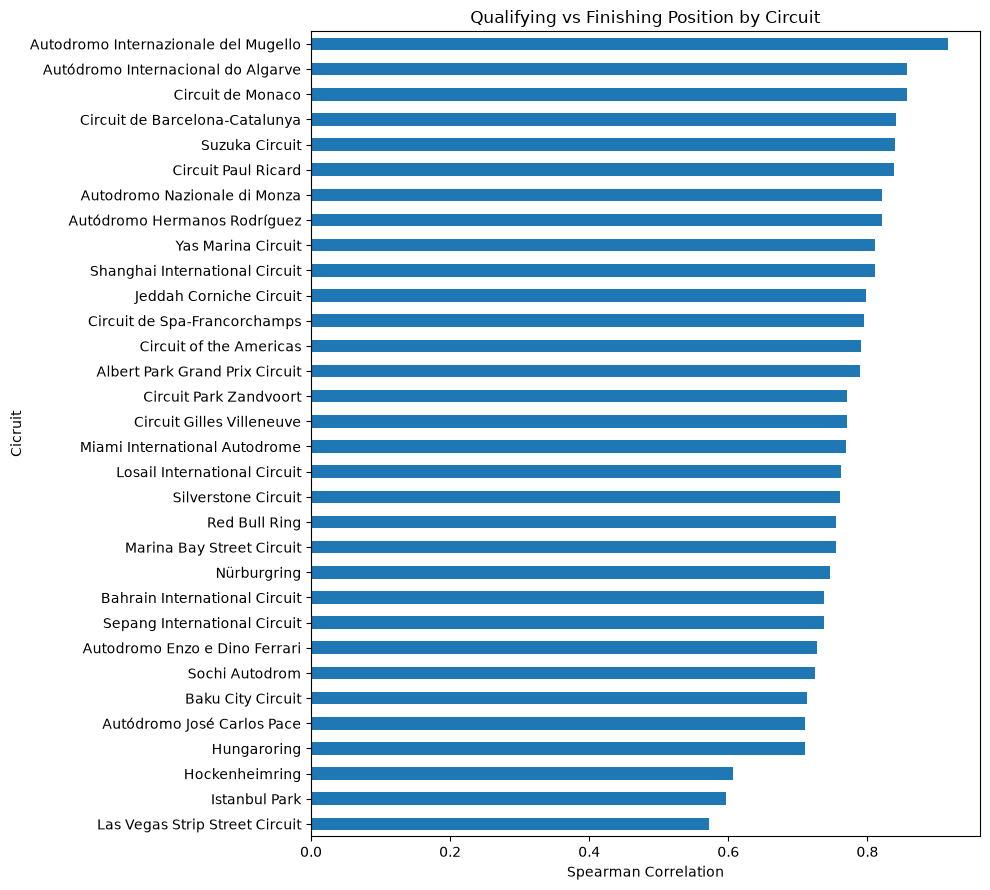

In [ ]:
# Create a bar chart of the above correlations
plt.figure(figsize=(10,9))
circuitCorr.sort_values().plot(kind="barh")
plt.xlabel("Spearman Correlation")
plt.ylabel("Circuit")
plt.title("Qualifying vs Finishing Position by Circuit")
plt.tight_layout()
plt.show()

I checked the number of races at each circuit (i.e. how many data points there are per circuit). This is important as circuits with fewer races may produce a less stable comaprison.

In [ ]:
# Count number of races at each circuit
noRacesPerCircuit = (analysisData.groupby("circuitName")["raceId"].nunique().sort_values(ascending=False))
noRacesPerCircuit

circuitName
Red Bull Ring                           13
Silverstone Circuit                     12
Bahrain International Circuit           12
Yas Marina Circuit                      11
Autodromo Nazionale di Monza            11
Hungaroring                             11
Circuit de Spa-Francorchamps            11
Circuit de Barcelona-Catalunya          11
Circuit de Monaco                       10
Autódromo José Carlos Pace              10
Circuit of the Americas                 10
Suzuka Circuit                           9
Marina Bay Street Circuit                9
Albert Park Grand Prix Circuit           9
Circuit Gilles Villeneuve                9
Autódromo Hermanos Rodríguez             9
Baku City Circuit                        8
Sochi Autodrom                           8
Shanghai International Circuit           7
Circuit Paul Ricard                      4
Sepang International Circuit             4
Circuit Park Zandvoort                   4
Hockenheimring                           4

To mitigate this, I tested the correlations where cricuits had at least three, five and seven races. This was to see if there was any significant difference or sway including circuits with less races may introduce into the analysis. 

In [ ]:
# Calculate thresholds to determine which circuits not to include 
for threshold in [3,5,7]:
    validCircuits = noRacesPerCircuit[noRacesPerCircuit >= threshold].index
    filteredCorr = circuitCorr.loc[validCircuits]
    print(f"\nmin {threshold} races: ",
          f"included circuits: {len(filteredCorr)}",
          f"range: {filteredCorr.min():.3f} to {filteredCorr.max():.3f}")


min 3 races:  included circuits: 27 range: 0.606 to 0.856

min 5 races:  included circuits: 19 range: 0.710 to 0.856

min 7 races:  included circuits: 19 range: 0.710 to 0.856


In [ ]:
# Display the circuits that would be removed, in case of meaningful data loss
excludedCircuits = noRacesPerCircuit[(noRacesPerCircuit >= 3) & (noRacesPerCircuit < 5)].index
print(circuitCorr.loc[excludedCircuits].sort_values())


circuitName
Hockenheimring                   0.606324
Autodromo Enzo e Dino Ferrari    0.726802
Sepang International Circuit     0.737913
Losail International Circuit     0.761990
Miami International Autodrome    0.769887
Circuit Park Zandvoort           0.770165
Jeddah Corniche Circuit          0.797471
Circuit Paul Ricard              0.838397
dtype: float64


I decided on a threshold of at least five races, to have a balance between retaining as many circuits as possible and excluding those with limited appearances. This left 19 circuits for the analysis. Those that were excluded can be seen in the list above. 

Here I can see that the circuit correlations range from approximately 0.7-0.86. This indicates that the relationship between qualifying and finishing position does vary between circuits.

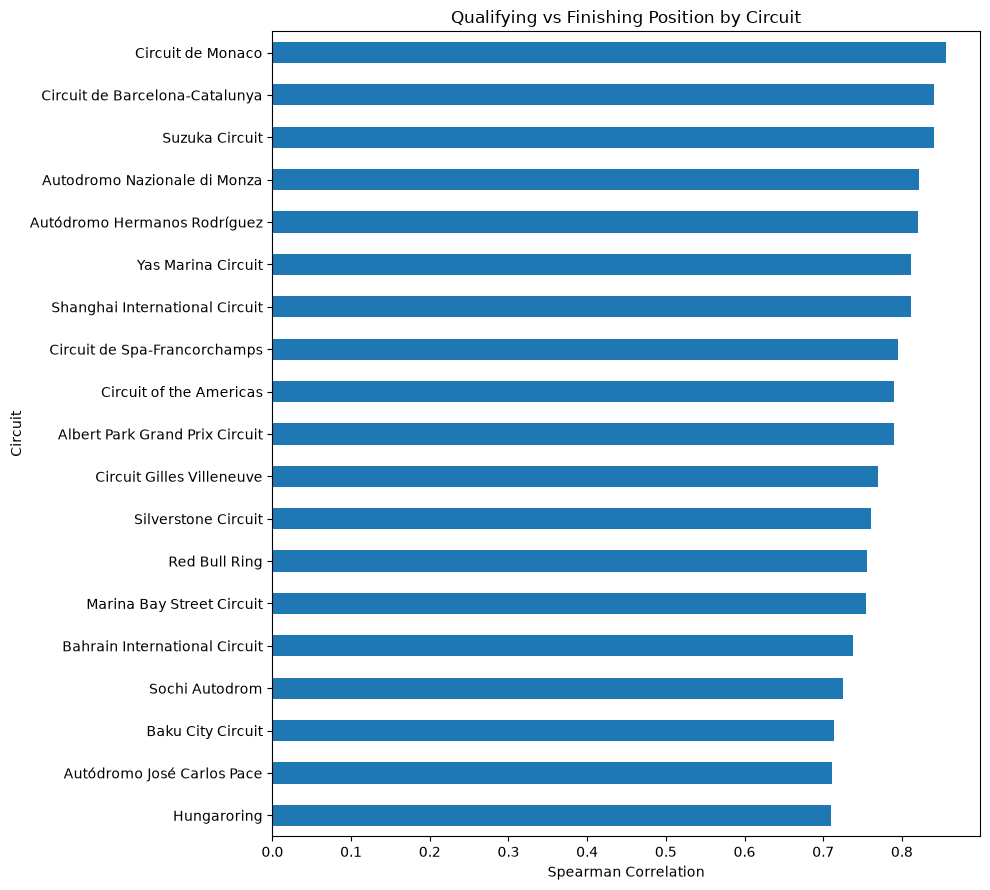

In [ ]:
validCircuits = noRacesPerCircuit[noRacesPerCircuit >= 5].index
validCircuitCorr = circuitCorr.loc[validCircuits].sort_values()

# Create bar chart of all valid circuit correlations
plt.figure(figsize=(10,9))
validCircuitCorr.sort_values().plot(kind="barh")
plt.xlabel("Spearman Correlation")
plt.ylabel("Circuit")
plt.title("Qualifying vs Finishing Position by Circuit")
plt.tight_layout()
plt.show()

I created a column containing absolute position differences using .abs() on positionDiff values. This is usefel as without it positive and negative changes in position would otherwise cancel eachother out. When averaged per circuit, a larger absolute value means that drivers typically finished further from their qualifying positions.

In [ ]:
# Add absolute position difference column
analysisData["absPositionDiff"] = analysisData["positionDiff"].abs()
# Calculate averge absoltue position change per circuit
circuitAbsDiff = (analysisData.groupby("circuitName")["absPositionDiff"].mean().loc[validCircuits].sort_values())
circuitAbsDiff

circuitName
Yas Marina Circuit                2.404145
Circuit de Barcelona-Catalunya    2.457286
Suzuka Circuit                    2.472050
Circuit de Monaco                 2.472727
Autódromo Hermanos Rodríguez      2.612903
Shanghai International Circuit    2.629921
Autodromo Nazionale di Monza      2.642105
Circuit de Spa-Francorchamps      2.790576
Circuit Gilles Villeneuve         2.953333
Silverstone Circuit               2.959799
Albert Park Grand Prix Circuit    2.977941
Circuit of the Americas           3.000000
Sochi Autodrom                    3.043478
Red Bull Ring                     3.096916
Autódromo José Carlos Pace        3.172619
Bahrain International Circuit     3.202899
Marina Bay Street Circuit         3.285714
Hungaroring                       3.324742
Baku City Circuit                 3.523077
Name: absPositionDiff, dtype: float64

For example, I can see that in Baku, on average a driver finished 3.5 positions away from where they qualified, and in Yas Marina, they finished 2.4 positions away. While this may not seem like a significant difference, even the tiniest of margins are important in F1, and can mean the difference between winning and losing a championship.

In [ ]:
# Comapre the average absolute difference values with the correlations per circuit
absCorrComparison = pd.DataFrame({"correlation": circuitCorr, "absoluteDifference": circuitAbsDiff}).dropna().sort_values(by=["correlation"])
absCorrComparison

,correlation,absoluteDifference
circuitName,,
Hungaroring,0.709649,3.324742
Autódromo José Carlos Pace,0.710760,3.172619
Baku City Circuit,0.713114,3.523077
Sochi Autodrom,0.725130,3.043478
Bahrain International Circuit,0.738252,3.202899
Marina Bay Street Circuit,0.754494,3.285714
Red Bull Ring,0.755277,3.096916
Silverstone Circuit,0.760569,2.959799
Circuit Gilles Villeneuve,0.769961,2.953333


Above I can see the correlations vs mean absolute differences. While the Spearman correlations measures rank association, the absolute difference measures the size of positional difference. These two measures compliment eachother well and provide a broader picture.

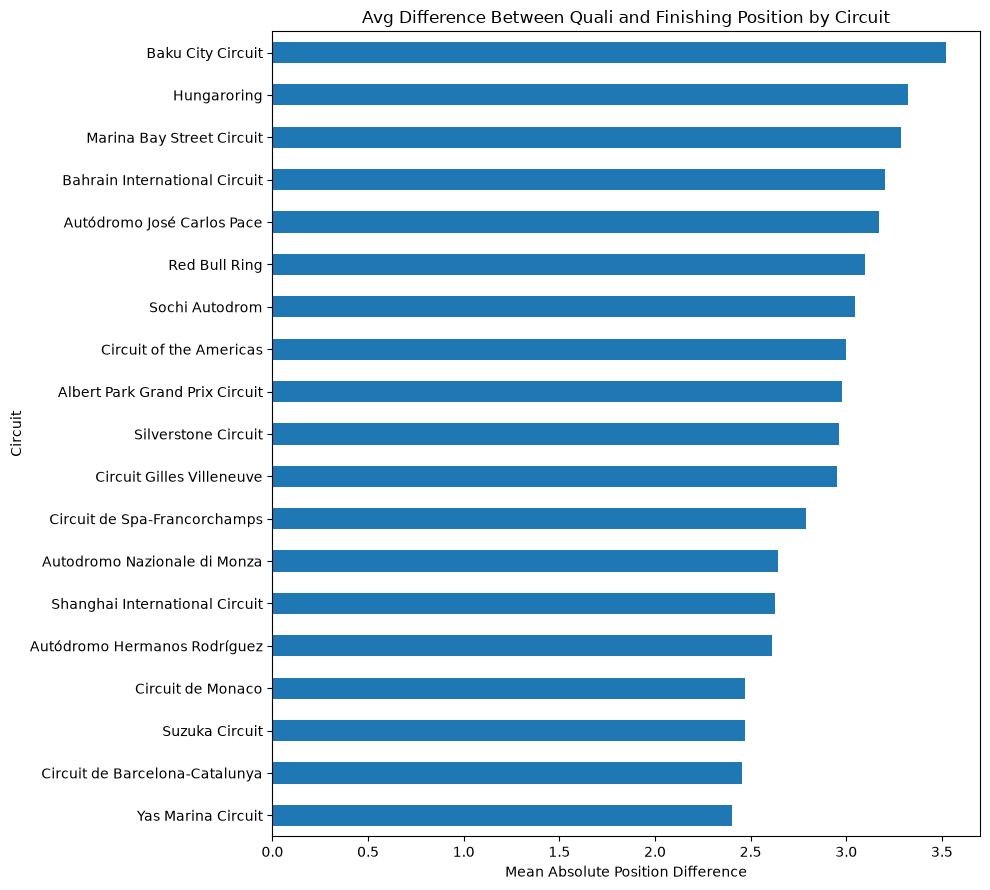

In [ ]:
# Create bar chart of absolute position difference per circuit
plt.figure(figsize=(10,9))
circuitAbsDiff.sort_values().plot(kind="barh")
plt.xlabel("Mean Absolute Position Difference")
plt.ylabel("Circuit")
plt.title("Avg Difference Between Quali and Finishing Position by Circuit")
plt.tight_layout()
plt.show()

These statistics were used to inform the creation of a shiny app, which displays appropriate visuals to help interpret the statistical results. In the shiny app I can view either the Spearman correlation or Absolute difference per circuit, as well as a scatter graph for each circuit individually.

# LIMITATIONS

- As mentioned, excluding records without numerical finishing positions may introduce selection bias, but including them would complicate my analysis as I would need to quantify non-standard finishing positions, which would lie outside of the expected ranking system.

- In F1 there are so many variables and 'extenuating circumstances' that has an impact on race results, accidents, incidents, weather, strategy and performance can all affect results, but involving all of these variables, many of which I do not have data for, is out of scope for this project.

- As explained, qualifying position is not necessarily the same as a driver's starting position.

- As explained, some circuits have had more races and thus contain more data for analysis than others, meaning strength of results per circuit may vary, the five race threshold improves this comparability but does not remove all uncertainty.

- A strong correlation does not necessarily reflect the accuracy of a potential predictive model. 